# 🧹 02 - Titanic Data Cleaning & Imputation Pipeline

This notebook handles data cleaning, missing value imputation, duplicate checks, and data type validation.

### Workflow:
1. Load raw dataset.
2. Impute `Embarked` missing values using the mode.
3. Impute `Age` missing values using conditional medians based on `Pclass` and passenger `Title`.
4. Handle `Fare` missing values using median fare.
5. Extract `Deck` information from `Cabin`.
6. Validate that no null values remain in key analytical features.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to path
sys.path.append(str(Path("..").resolve()))
from src.preprocessing import TitanicPreprocessor, extract_title_raw
from src.data_loader import load_raw_data

raw_df = load_raw_data("../data/raw/train.csv")
print(f"Raw data loaded: {raw_df.shape}")


Raw data loaded: (891, 12)


## 1. Inspect Initial Missing Values

In [2]:
print("Missing values before cleaning:")
print(raw_df.isnull().sum()[raw_df.isnull().sum() > 0])


Missing values before cleaning:
Age         177
Cabin       687
Embarked      2
dtype: int64


## 2. Title-Aware Age Imputation
Instead of imputing Age with a single global median, we extract passenger titles (`Mr`, `Mrs`, `Miss`, `Master`, `Officer`, `Royalty`) and compute the median age for each `(Pclass, Title)` subgroup.


In [3]:
# Extract title
raw_df["Title"] = extract_title_raw(raw_df["Name"])
grouped_age = raw_df.groupby(["Pclass", "Title"])["Age"].agg(["count", "median", "mean"]).round(1)
print("Median Age by Pclass and Title Subgroups:")
grouped_age


Median Age by Pclass and Title Subgroups:


count  median  mean
Pclass Title                       
1      Master       3     4.0   5.3
       Miss        47    30.0  29.7
       Mr          87    40.0  41.6
       Mrs         35    40.0  40.4
       Officer      9    50.0  50.9
       Royalty      5    40.0  41.6
2      Master       9     1.0   2.3
       Miss        33    24.0  22.6
       Mr          82    31.0  32.8
       Mrs         41    32.0  33.7
       Officer      8    46.5  42.0
3      Master      24     4.0   5.4
       Miss        69    18.0  16.1
       Mr         229    26.0  28.7
       Mrs         33    31.0  33.5

## 3. Applying the Preprocessing Transformer

In [4]:
preprocessor = TitanicPreprocessor()
clean_df = preprocessor.fit_transform(raw_df)

print("Preprocessed DataFrame Head:")
clean_df.head()


Preprocessed DataFrame Head:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Deck
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S,Mr,Unknown
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S,Miss,Unknown
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs,C
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S,Mr,Unknown


## 4. Verification: Missing Values Post-Cleaning

In [5]:
print("Missing values after cleaning:")
print(clean_df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Deck", "Title"]].isnull().sum())


Missing values after cleaning:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
Deck        0
Title       0
dtype: int64


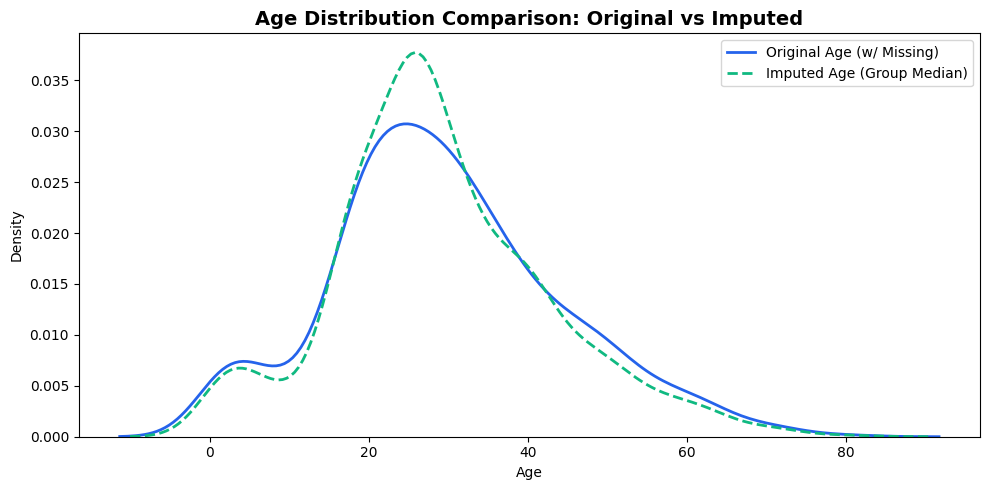

In [6]:
# Compare Age distribution before and after imputation
fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(raw_df["Age"].dropna(), label="Original Age (w/ Missing)", color="#2563EB", lw=2, ax=ax)
sns.kdeplot(clean_df["Age"], label="Imputed Age (Group Median)", color="#10B981", linestyle="--", lw=2, ax=ax)
ax.set_title("Age Distribution Comparison: Original vs Imputed", fontsize=14, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()


## Summary of Data Cleaning:
- Imputed 177 missing `Age` values using `(Pclass, Title)` medians.
- Imputed 2 missing `Embarked` values with mode (`'S'`).
- Converted `Cabin` column into structured `Deck` categorical feature.
- Verified dataset integrity with zero remaining nulls.
